In [13]:
import tensorflow as tf
import pandas as pd
from tensorflow import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer



# Trabalho 2 — Redes Neurais Artificiais

Vídeo de apresentação

A apresentação do trabalho está disponível no link abaixo:

https://drive.google.com/file/d/1uloelKBn85kua6HPNxi5TzkPvkVpbUIy/view?usp=sharing

## 1. Descrição do problema

O objetivo deste trabalho é desenvolver uma rede neural artificial do tipo Multilayer Perceptron (MLP), utilizando a biblioteca Keras, para prever a sobrevivência de passageiros do Titanic.

O problema é caracterizado como uma tarefa de **classificação binária**, pois a variável-alvo `Survived` apresenta duas possibilidades:

- **0:** o passageiro não sobreviveu.
- **1:** o passageiro sobreviveu.

O conjunto de dados foi obtido na plataforma Kaggle, na competição *Titanic — Machine Learning from Disaster*.

O dataset contém 891 registros e 12 colunas, incluindo características numéricas e categóricas dos passageiros. Também apresenta valores faltantes, que serão tratados durante a etapa de pré-processamento.

## 2. Análise exploratória dos dados

Nesta etapa, foram analisadas as características gerais do conjunto de dados Titanic, incluindo suas dimensões, tipos de variáveis e presença de valores ausentes.

A análise foi realizada utilizando a biblioteca Pandas, por meio dos métodos `shape`, `info()`, `isnull().sum()` e `value_counts()`.

Essas informações são importantes para identificar quais transformações serão necessárias durante o pré-processamento, antes do treinamento da rede neural artificial.

In [14]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
#infos gerais dos dados
df.info()

#quantidade de linhas e colunas
print("Dim do dataset:",df.shape)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
Dim do dataset: (891, 12)


In [16]:
#verificar valores faltantes em cada coluna
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [17]:
#qtd de passageiros por classe
print(df["Survived"].value_counts())

#Distribuição Percentual
print(df["Survived"].value_counts(normalize=True) * 100)


Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


### Distribuição da variável-alvo

A análise da variável Survived revelou que, dos 891 passageiros presentes no dataset, 549 (61,62%) não sobreviveram e 342 (38,38%) sobreviveram.

Portanto, a classe 0 é majoritária, indicando um desbalanceamento moderado entre as classes.

Essa característica deve ser considerada na avaliação do modelo, pois a acurácia isoladamente pode não representar adequadamente sua capacidade de identificar passageiros sobreviventes. Por isso, também serão analisadas métricas como precision, recall e F1-score.

## 3. Pré-processamento dos dados

Nesta etapa, serão realizadas transformações nas variáveis preditoras para prepará-las para o treinamento da rede neural artificial.

O pré-processamento será composto por três operações principais:

- **Imputação:** preenchimento de valores ausentes.
- **Codificação:** transformação de variáveis categóricas em representações numéricas.
- **Padronização:** transformação das variáveis numéricas para escalas comparáveis.

As transformações serão ajustadas exclusivamente com os dados de treinamento, evitando vazamento de informações dos conjuntos de validação e teste.

In [18]:
#selecionar variáveis preditoras

features = ["Pclass","Sex","Age","SibSp","Parch", "Fare","Embarked"]
X = df[features]

#selecionar váriavel alvo
y = df["Survived"]

print("Váriaveis preditoras:",X.shape)
print("Váriavel alvo:",y.shape)


Váriaveis preditoras: (891, 7)
Váriavel alvo: (891,)


In [19]:
#separar 70% treino e 30% para validação e teste
X_train,X_temp,y_train,y_temp = train_test_split(
    X,y,
    test_size=0.3,
    random_state=42,
    stratify = y,
)

#dividir os 30% restantes
X_val,X_test,y_val,y_test = train_test_split(
    X_temp,y_temp,
    test_size=0.5,
    random_state=42,
    stratify = y_temp,
)

print("Treinamento:", X_train.shape)
print("Validação: ", X_val.shape)
print("Teste: ", X_test.shape)

Treinamento: (623, 7)
Validação:  (134, 7)
Teste:  (134, 7)


In [20]:
#variáveis numéricas
num_features = ["Age","SibSp","Parch","Fare"]

#variáveis categóricas
cat_features = ["Pclass","Sex","Embarked"]
print("Numéricas",num_features)
print("Categóricas",cat_features)

Numéricas ['Age', 'SibSp', 'Parch', 'Fare']
Categóricas ['Pclass', 'Sex', 'Embarked']


In [21]:
#pipeline para variáveis numéricas
num_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

#pipeline para variáveis categóricas
cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])

#combinar os pipelines
preprocessor = ColumnTransformer([
    ("num",num_pipeline,num_features),
    ("cat",cat_pipeline,cat_features)
])




### Justificativa das técnicas de pré-processamento

Para tratar os valores ausentes das variáveis numéricas, foi utilizada a mediana, por ser menos sensível a valores extremos. Nas variáveis categóricas, foi utilizada a moda, que representa a categoria mais frequente.

As variáveis categóricas foram transformadas por meio de One-Hot Encoding, permitindo sua utilização pela rede neural. Já as variáveis numéricas foram padronizadas utilizando StandardScaler, facilitando o processo de otimização.

As transformações foram ajustadas somente com os dados de treinamento, evitando vazamento de informações dos conjuntos de validação e teste.

In [22]:
#ajustar e transformar somente os dados de treinamento
X_train_processed = preprocessor.fit_transform(X_train)
#Aplicar as mesmas transformações
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Treinamento:", X_train_processed.shape)
print("Validação: ", X_val_processed.shape)
print("Teste: ", X_test_processed.shape)


Treinamento: (623, 12)
Validação:  (134, 12)
Teste:  (134, 12)


## 4. Construção e treinamento do modelo

Nesta etapa, será construída uma rede neural artificial do tipo Multilayer Perceptron (MLP), utilizando Keras com TensorFlow.

A arquitetura inicial será composta por duas camadas ocultas, contendo 32 e 16 neurônios, respectivamente, ambas utilizando a função de ativação ReLU.

A camada de saída terá um neurônio com função sigmoid, adequada para estimar a probabilidade de sobrevivência dos passageiros.

A arquitetura será avaliada por meio do desempenho nos conjuntos de treinamento, validação e teste.

In [23]:
# Definir uma semente para reprodutibilidade
keras.utils.set_random_seed(42)

# Construção da rede neural
modelo = keras.Sequential([
    layers.Input(shape=(X_train_processed.shape[1],)),

    # Primeira camada oculta
    layers.Dense(32, activation="relu"),

    # Segunda camada oculta
    layers.Dense(16, activation="relu"),

    # Camada de saída
    layers.Dense(1, activation="sigmoid")
])

# Visualizar a arquitetura
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961 (3.75 KB)

 Trainable params: 961 (3.75 KB)

 Non-trainable params: 0 (0.00 B)

In [24]:
#compilação da rede neural
modelo.compile(
    optimizer = keras.optimizers.Adam(learning_rate=0.001),
    loss = "binary_crossentropy",
    metrics = ["accuracy"]
)
print("compilado")

compilado


In [25]:
#callback para interromper o treinamento
early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 5,
    restore_best_weights = True
)

#treinamento da rede neural
historico = modelo.fit(
    X_train_processed,
    y_train,
    validation_data = (X_val_processed,y_val),
    epochs = 100,
    batch_size = 32,
    callbacks = [early_stopping],
    verbose = 1
)


Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7047 - loss: 0.5975 - val_accuracy: 0.7313 - val_loss: 0.5521
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7352 - loss: 0.5446 - val_accuracy: 0.7537 - val_loss: 0.5093
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7592 - loss: 0.5076 - val_accuracy: 0.7836 - val_loss: 0.4724
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7785 - loss: 0.4793 - val_accuracy: 0.7836 - val_loss: 0.4413
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7817 - loss: 0.4587 - val_accuracy: 0.7985 - val_loss: 0.4176
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8074 - loss: 0.4432 - val_accuracy: 0.8358 - val_loss: 0.3974
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8058 - loss: 0.4316 - val_accuracy: 0.8731 - val_loss: 0.3832
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8042 - loss: 0.4238 - val_accuracy: 0.8731 - 

## 5. Análise das curvas de aprendizagem

Nesta etapa, serão analisadas as curvas de perda (loss) e acurácia (accuracy) dos conjuntos de treinamento e validação.

Esses gráficos permitem observar o comportamento da rede neural durante o treinamento e identificar possíveis sinais de overfitting ou underfitting.

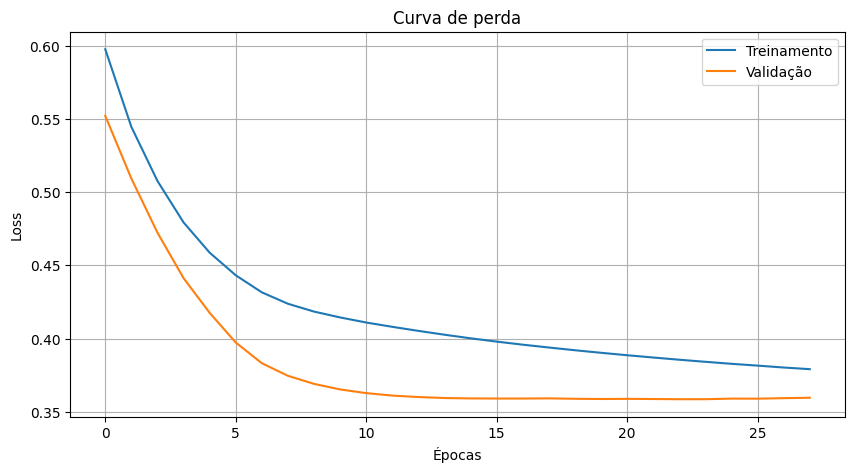

In [26]:
plt.figure(figsize=(10,5))

plt.plot(historico.history["loss"],label="Treinamento")
plt.plot(historico.history["val_loss"],label="Validação")

plt.title("Curva de perda")
plt.ylabel("Loss")
plt.xlabel("Épocas")
plt.legend()
plt.grid(True)

plt.show()

### Análise da curva de perda

O gráfico apresenta uma redução progressiva da perda de treinamento e validação durante as primeiras épocas, indicando que a rede neural conseguiu aprender padrões presentes nos dados.

A perda de validação apresentou valores inferiores aos da perda de treinamento e começou a se estabilizar aproximadamente entre as épocas 15 e 20.

Nas últimas épocas, observou-se uma pequena elevação da perda de validação, enquanto a perda de treinamento continuou diminuindo, o que pode indicar o início de overfitting.

Entretanto, não foram observados sinais acentuados de sobreajuste ou subajuste. O uso do EarlyStopping permitiu interromper o treinamento após a ausência de melhorias na perda de validação e restaurar os melhores pesos encontrados.

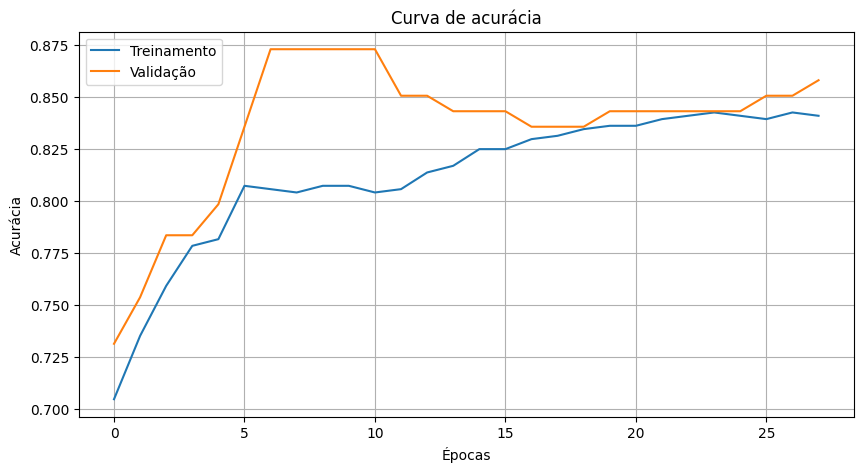

In [27]:
plt.figure(figsize=(10,5))

plt.plot(historico.history["accuracy"],label="Treinamento")
plt.plot(historico.history["val_accuracy"],label="Validação")

plt.title("Curva de acurácia")
plt.ylabel("Acurácia")
plt.xlabel("Épocas")
plt.legend()
plt.grid(True)

plt.show()

### Análise da curva de acurácia

A curva de acurácia demonstra que a rede neural apresentou uma evolução positiva durante o treinamento.

Nas primeiras épocas, houve um aumento significativo da acurácia nos conjuntos de treinamento e validação, indicando que o modelo estava aprendendo padrões relevantes dos dados.

Ao longo das épocas seguintes, a acurácia de treinamento continuou aumentando gradualmente, enquanto a acurácia de validação apresentou algumas oscilações, mantendo-se em valores relativamente próximos.

Considerando conjuntamente as curvas de perda e acurácia, não foram identificados sinais acentuados de overfitting ou underfitting. Entretanto, a estabilização da perda de validação nas últimas épocas sugere que continuar o treinamento poderia não produzir melhorias relevantes.

O uso do EarlyStopping ajudou a interromper o treinamento quando a perda de validação deixou de apresentar melhorias.

## 6. Avaliação final do modelo

Nesta etapa, o modelo será avaliado utilizando o conjunto de teste, que não participou do treinamento nem da seleção dos melhores pesos.

Serão calculadas métricas de classificação, como acurácia, precisão, recall e F1-score, para analisar o desempenho e a capacidade de generalização da rede neural.

In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Probabilidades previstas pela rede neural
y_prob = modelo.predict(X_test_processed).ravel()

# Converter probabilidades em classes (0 ou 1)
y_pred = (y_prob >= 0.5).astype(int)

# Calcular as métricas
print("Acurácia:", accuracy_score(y_test, y_pred))
print("Precisão:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nMatriz de confusão:")
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
Acurácia: 0.753731343283582
Precisão: 0.7045454545454546
Recall: 0.6078431372549019
F1-score: 0.6526315789473685

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.78      0.84      0.81        83
           1       0.70      0.61      0.65        51

    accuracy                           0.75       134
   macro avg       0.74      0.73      0.73       134
weighted avg       0.75      0.75      0.75       134


Matriz de confusão:
[[70 13]
 [20 31]]


In [29]:
val_loss, val_accuracy = modelo.evaluate(
    X_val_processed,
    y_val,
    verbose=0
)

print(f"Acurácia de validação: {val_accuracy:.2%}")
print(f"Perda de validação: {val_loss:.4f}")

Acurácia de validação: 84.33%
Perda de validação: 0.3586


### Análise dos resultados no conjunto de teste

A rede neural MLP foi avaliada utilizando 134 exemplos do conjunto de teste, que não participaram do treinamento nem da seleção dos melhores pesos.

O modelo apresentou acurácia de aproximadamente **75,37%**, classificando corretamente 101 passageiros e incorretamente 33.

Para a classe positiva (sobreviveu), foram obtidas precisão de **70,45%**, recall de **60,78%** e F1-score de **65,26%**.

A matriz de confusão apresentou 70 verdadeiros negativos, 13 falsos positivos, 20 falsos negativos e 31 verdadeiros positivos.

Esses resultados indicam que o modelo apresentou capacidade de generalização, embora seu desempenho tenha sido inferior ao observado durante a validação. Além disso, a rede apresentou maior dificuldade para identificar corretamente os passageiros sobreviventes.

Portanto, apesar de ter aprendido padrões relevantes dos dados, ainda existe espaço para melhorar o desempenho do modelo, especialmente o recall da classe positiva.

In [30]:
val_loss, val_accuracy = modelo.evaluate(
    X_val_processed,
    y_val,
    verbose=0
)

test_loss, test_accuracy = modelo.evaluate(
    X_test_processed,
    y_test,
    verbose=0
)

print(f"Acurácia de validação: {val_accuracy:.2%}")
print(f"Acurácia de teste: {test_accuracy:.2%}")

print(f"Perda de validação: {val_loss:.4f}")
print(f"Perda de teste: {test_loss:.4f}")

Acurácia de validação: 84.33%
Acurácia de teste: 75.37%
Perda de validação: 0.3586
Perda de teste: 0.4981


## 7. Conclusão

Inicialmente, foi realizado o pré-processamento dos dados, incluindo o tratamento de valores ausentes, a codificação de variáveis categóricas e a padronização das variáveis numéricas. Os dados foram divididos em conjuntos de treinamento (70%), validação (15%) e teste (15%).

A arquitetura utilizada possui duas camadas ocultas, com 32 e 16 neurônios, utilizando a função de ativação ReLU, e uma camada de saída com ativação sigmoid.

Durante o treinamento, foi utilizado o callback EarlyStopping, permitindo interromper o processo após a ausência de melhorias na perda de validação e recuperar os melhores pesos.

As curvas de aprendizagem demonstraram uma redução progressiva das perdas e um aumento da acurácia, indicando que o modelo conseguiu aprender padrões presentes nos dados. Não foram identificados sinais acentuados de overfitting ou underfitting, embora a perda de validação tenha apresentado estabilização nas últimas épocas.

Na avaliação final, o modelo apresentou acurácia de 84,33% na validação e 75,37% no teste. Para a classe dos passageiros sobreviventes, foram obtidos precisão de 70,45%, recall de 60,78% e F1-score de 65,26%.

A diferença entre os resultados de validação e teste indica que o modelo apresenta limitações de generalização. A matriz de confusão também demonstrou maior dificuldade na identificação dos passageiros sobreviventes.

Conclui-se que a MLP conseguiu aprender relações relevantes entre as características dos passageiros e sua sobrevivência, apresentando desempenho razoável no conjunto de teste. Como possíveis melhorias futuras, poderiam ser investigadas outras arquiteturas, técnicas de regularização e estratégias de ajuste de hiperparâmetros, utilizando dados de validação apropriados.